# 01 - EDA: ingresos mensuales por canal (AdventureWorks2025)

Objetivo: tomar decisiones de modelado (recortes, transformaciones, estacionalidad, variables). Serie corta (~35 meses por canal): las conclusiones son indicativas.

## 0. Configuración y carga

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path.cwd() / "data" / "raw" / "raw_revenue_features.csv"
REGIME_CHANGE = pd.Timestamp("2024-06-01")  # cambio de régimen online (6-7/2024)

df = pd.read_csv(DATA_PATH , parse_dates=["month_start", "first_order_date", "last_order_date"])
df["revenue"] = df["revenue"].astype(float)
df.head()

,month_start,channel,orders,revenue,units,customers,active_days,first_order_date,last_order_date
0,2022-05-01,online,9,2.840886e+04,9,9,2,2022-05-30,2022-05-31
1,2022-05-01,reseller,38,4.893286e+05,820,38,1,2022-05-30,2022-05-30
2,2022-06-01,online,142,4.628707e+05,142,142,30,2022-06-01,2022-06-30
3,2022-06-01,reseller,75,1.538408e+06,2053,75,1,2022-06-30,2022-06-30
4,2022-07-01,online,155,5.026134e+05,155,155,30,2022-07-01,2022-07-31


## 1. Calidad de datos

In [15]:
print(df.dtypes)
print("Nulos:\n", df.isna().sum())
print("Duplicados (mes, canal):", df.duplicated(["month_start", "channel"]).sum())
print(df.groupby("channel")["month_start"].agg(["min", "max", "count"]))

month_start         datetime64[us]
channel                        str
orders                       int64
revenue                    float64
units                        int64
customers                    int64
active_days                  int64
first_order_date    datetime64[us]
last_order_date     datetime64[us]
dtype: object
Nulos:
 month_start         0
channel             0
orders              0
revenue             0
units               0
customers           0
active_days         0
first_order_date    0
last_order_date     0
dtype: int64
Duplicados (mes, canal): 0
                min        max  count
channel                              
online   2022-05-01 2025-06-01     38
reseller 2022-05-01 2025-04-01     36


Meses incompletos: revisar `active_days`, `first_order_date` y `last_order_date` en los bordes de cada canal.

In [16]:
cols = ["month_start", "channel", "orders", "revenue", "active_days", "first_order_date", "last_order_date"]
for ch, g in df.groupby("channel"):
    print(ch)
    print(g[cols].head(3).to_string(index=False))
    print(g[cols].tail(3).to_string(index=False))
    print()

online
month_start channel  orders     revenue  active_days first_order_date last_order_date
 2022-05-01  online       9  28408.8582            2       2022-05-30      2022-05-31
 2022-06-01  online     142 462870.6548           30       2022-06-01      2022-06-30
 2022-07-01  online     155 502613.4212           30       2022-07-01      2022-07-31
month_start channel  orders    revenue  active_days first_order_date last_order_date
 2025-04-01  online    2098 1805994.88           30       2025-04-01      2025-04-30
 2025-05-01  online    2218 1908059.49           31       2025-05-01      2025-05-31
 2025-06-01  online     905   47491.55           29       2025-06-01      2025-06-29

reseller
month_start  channel  orders      revenue  active_days first_order_date last_order_date
 2022-05-01 reseller      38 4.893286e+05            1       2022-05-30      2022-05-30
 2022-06-01 reseller      75 1.538408e+06            1       2022-06-30      2022-06-30
 2022-07-01 reseller      60 1.1658

Constantes de recorte (se aplican aquí solo para el análisis; el raw no se modifica).

In [17]:
PERIODS = {
    "reseller": ("2022-06-01", "2025-04-01"),
    "online": ("2022-06-01", "2025-05-01"),
}

clean = pd.concat(
    [
        g[(g["month_start"] >= start) & (g["month_start"] <= end)]
        for ch, (start, end) in PERIODS.items()
        for g in [df[df["channel"] == ch]]
    ]
)
clean["avg_ticket"] = clean["revenue"] / clean["orders"]
print(clean.groupby("channel").size())

channel
online      36
reseller    35
dtype: int64


## 2. Serie de ingresos por canal

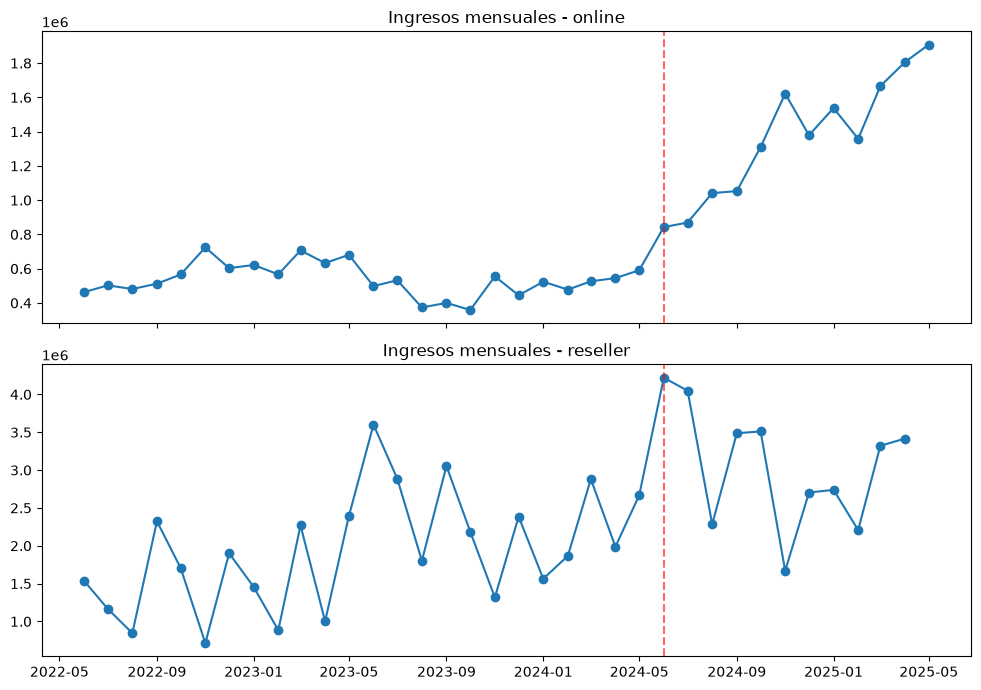

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (ch, g) in zip(axes, clean.groupby("channel")):
    ax.plot(g["month_start"], g["revenue"], marker="o")
    ax.set_title(f"Ingresos mensuales - {ch}")
    ax.axvline(REGIME_CHANGE, color="red", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 3. Descomposición: pedidos x ticket medio

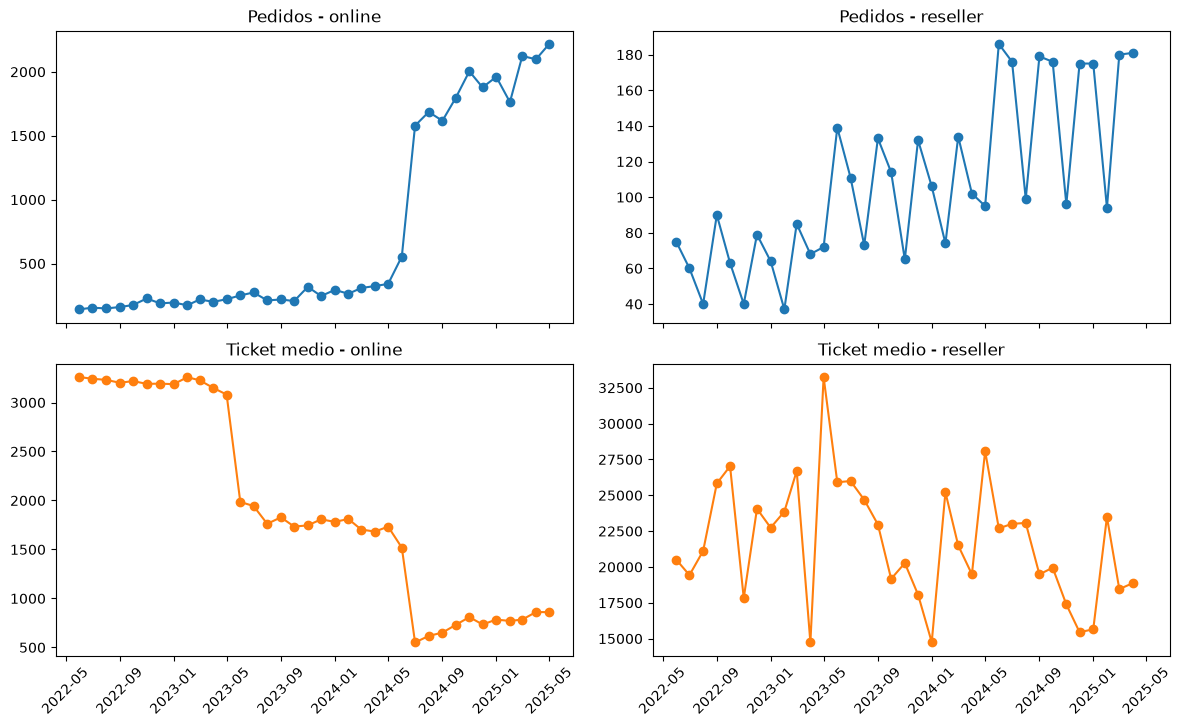

channel            
online    orders       0.947618
          units        0.950549
          customers    0.948947
          revenue      1.000000
reseller  orders       0.896708
          units        0.935434
          customers    0.896089
          revenue      1.000000
Name: revenue, dtype: float64

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for j, (ch, g) in enumerate(clean.groupby("channel")):
    axes[0, j].plot(g["month_start"], g["orders"], marker="o")
    axes[0, j].set_title(f"Pedidos - {ch}")
    axes[1, j].plot(g["month_start"], g["avg_ticket"], marker="o", color="tab:orange")
    axes[1, j].set_title(f"Ticket medio - {ch}")
    
plt.tight_layout()
for ax in axes.flatten():
    ax.xaxis.set_tick_params(rotation=45)
plt.show()

clean.groupby("channel")[["orders", "units", "customers", "revenue"]].corr()["revenue"]

## 4. Estacionalidad (mes vs año)

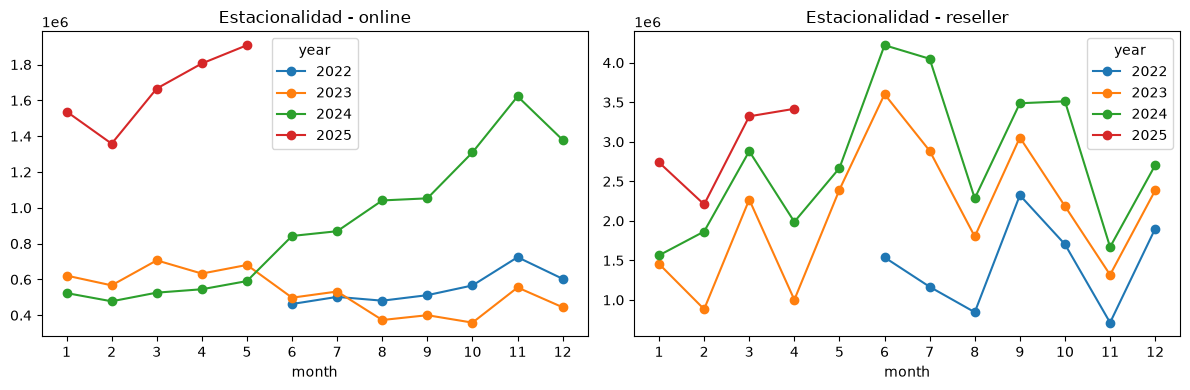

In [20]:
clean["year"] = clean["month_start"].dt.year
clean["month"] = clean["month_start"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (ch, g) in zip(axes, clean.groupby("channel")):
    pivot = g.pivot(index="month", columns="year", values="revenue")
    pivot.plot(ax=ax, marker="o")
    ax.set_title(f"Estacionalidad - {ch}")
    ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

## 5. Tendencia y autocorrelación

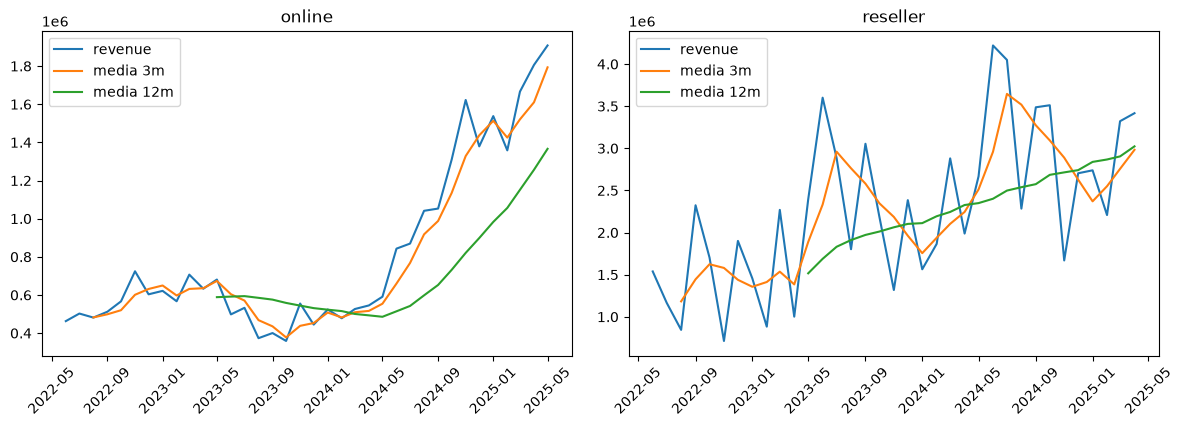

online {1: np.float64(0.95), 2: np.float64(0.94), 3: np.float64(0.88), 4: np.float64(0.86), 5: np.float64(0.81), 6: np.float64(0.74), 7: np.float64(0.66), 8: np.float64(0.53), 9: np.float64(0.39), 10: np.float64(0.18), 11: np.float64(-0.05), 12: np.float64(-0.3)}
reseller {1: np.float64(0.39), 2: np.float64(0.22), 3: np.float64(0.58), 4: np.float64(0.12), 5: np.float64(-0.03), 6: np.float64(0.31), 7: np.float64(0.01), 8: np.float64(0.01), 9: np.float64(0.54), 10: np.float64(0.22), 11: np.float64(0.01), 12: np.float64(0.8)}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (ch, g) in zip(axes, clean.groupby("channel")):
    s = g.set_index("month_start")["revenue"]
    ax.plot(s, label="revenue")
    ax.plot(s.rolling(3).mean(), label="media 3m")
    ax.plot(s.rolling(12).mean(), label="media 12m")
    ax.set_title(ch)
    ax.legend()
plt.tight_layout()
for ax in axes.flatten():
    ax.xaxis.set_tick_params(rotation=45)
plt.show()

for ch, g in clean.groupby("channel"):
    s = g.set_index("month_start")["revenue"]
    print(ch, {lag: round(s.autocorr(lag), 2) for lag in range(1, 13)})

## 5b. ACF/PACF con bandas de significancia

Online sobre `diff(log)` (sin tendencia) y reseller sobre niveles. Las bandas (95%) indican qué lags superan el ruido.

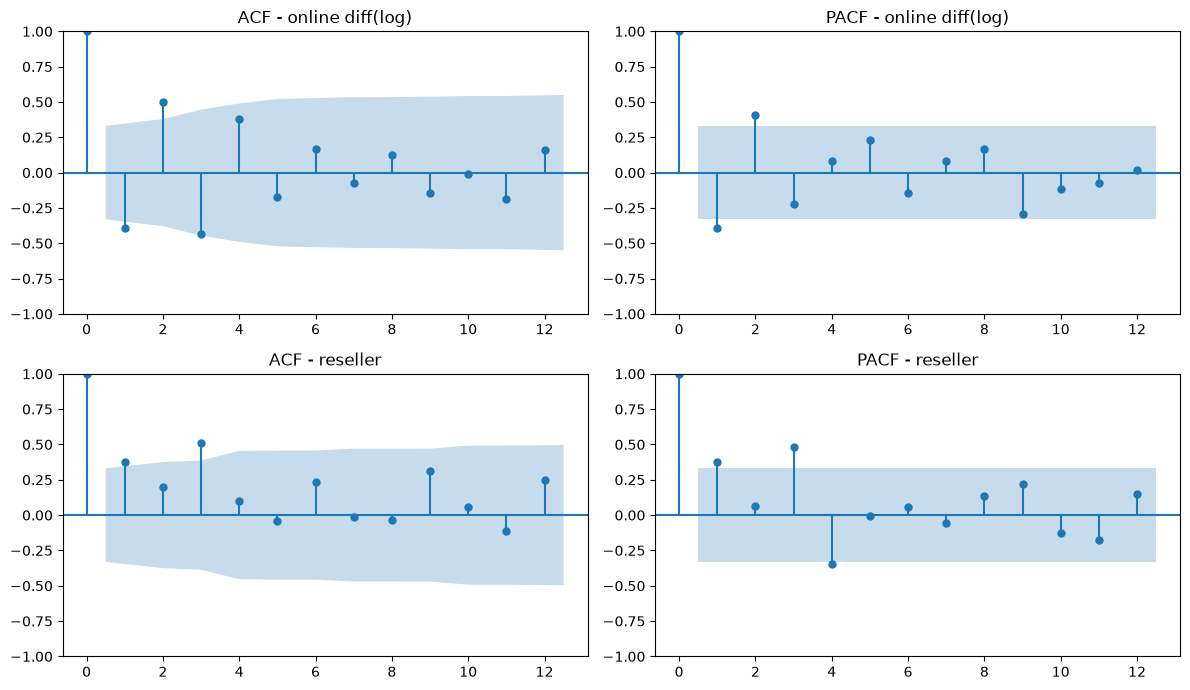

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

series = {
    "online diff(log)": np.log(clean[clean["channel"] == "online"].set_index("month_start")["revenue"]).diff().dropna(),
    "reseller": clean[clean["channel"] == "reseller"].set_index("month_start")["revenue"],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, (name, s) in enumerate(series.items()):
    plot_acf(s, lags=12, ax=axes[i, 0], title=f"ACF - {name}")
    plot_pacf(s, lags=12, ax=axes[i, 1], method="ywm", title=f"PACF - {name}")
plt.tight_layout()
plt.show()

## 5c. Reseller: boxplot por trimestre y ticket medio

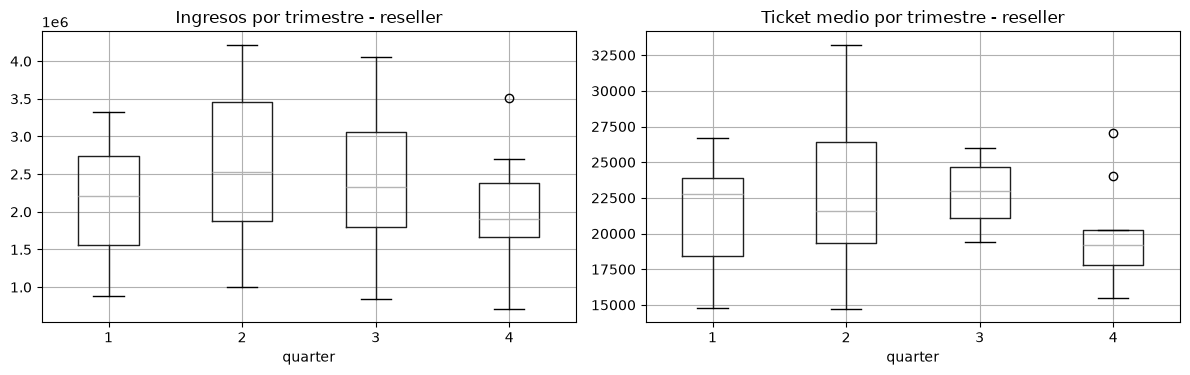

         orders  avg_ticket    revenue
quarter                               
1         105.0     21372.0  2131735.0
2         115.0     22942.0  2603510.0
3         107.0     22842.0  2432916.0
4         104.0     19912.0  2009826.0


In [10]:
res = clean[clean["channel"] == "reseller"].copy()
res["quarter"] = res["month_start"].dt.quarter

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
res.boxplot(column="revenue", by="quarter", ax=axes[0])
axes[0].set_title("Ingresos por trimestre - reseller")
res.boxplot(column="avg_ticket", by="quarter", ax=axes[1])
axes[1].set_title("Ticket medio por trimestre - reseller")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(res.groupby("quarter")[["orders", "avg_ticket", "revenue"]].mean().round(0))

## 6. Transformaciones: original vs log (online)

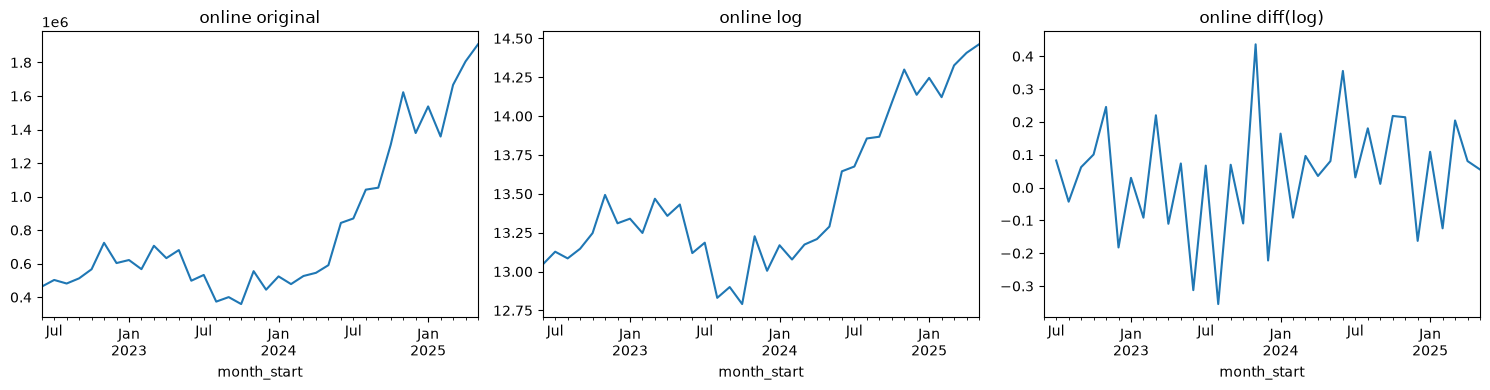

In [11]:
on = clean[clean["channel"] == "online"].set_index("month_start")["revenue"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
on.plot(ax=axes[0], title="online original")
np.log(on).plot(ax=axes[1], title="online log")
np.log(on).diff().plot(ax=axes[2], title="online diff(log)")
plt.tight_layout()
plt.show()

## 7. Baselines exploratorios (referencia, sin entrenar)

In [12]:
def evaluate(df_eval: pd.DataFrame, pred_col: str) -> dict:
    """MAE, RMSE y MAPE de una columna de pron?stico contra 'actual'."""
    err = df_eval["actual"] - df_eval[pred_col]
    return {
        "MAE": err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAPE": (err.abs() / df_eval["actual"]).mean() * 100,
    }


def baseline_table(s: pd.Series, h: int) -> pd.DataFrame:
    """Pron?sticos a h meses; el origen de cada fila es T-h (sin leakage)."""
    slope = s.diff().expanding().mean()  # pendiente media conocida en cada mes
    return pd.DataFrame({
        "actual": s,
        "naive": s.shift(h),
        "snaive": s.shift(12),
        "drift": s.shift(h) + h * slope.shift(h),
    }).dropna()  # misma muestra para todos los baselines


rows = []
for ch, g in clean.groupby("channel"):
    s = g.set_index("month_start")["revenue"]
    for h in (1, 6, 12):
        tabla = baseline_table(s, h)
        muestras = {"todo": tabla}
        if ch == "online":
            muestras["pre_quiebre"] = tabla[tabla.index < REGIME_CHANGE]
            muestras["post_quiebre"] = tabla[tabla.index >= REGIME_CHANGE]
        for nombre, t in muestras.items():
            for modelo in ["naive", "snaive", "drift"]:
                rows.append({"channel": ch, "h": h, "muestra": nombre, "n": len(t),
                             "baseline": modelo, **evaluate(t, modelo)})

resumen = pd.DataFrame(rows)
resumen.round(1)

,channel,h,muestra,n,baseline,MAE,RMSE,MAPE
0,online,1,todo,24,naive,131353.4,161403.4,15.5
1,online,1,todo,24,snaive,497122.8,665667.7,43.6
2,online,1,todo,24,drift,126451.7,157442.5,15.4
3,online,1,pre_quiebre,12,naive,82476.5,102586.8,17.4
4,online,1,pre_quiebre,12,snaive,113768.9,125496.0,24.7
5,online,1,pre_quiebre,12,drift,85235.0,107745.8,18.1
6,online,1,post_quiebre,12,naive,180230.4,203907.0,13.5
7,online,1,post_quiebre,12,snaive,880476.6,932993.9,62.5
8,online,1,post_quiebre,12,drift,167668.5,194851.6,12.7
9,online,6,todo,24,naive,339772.9,426515.6,36.0


## 8. Conclusiones

Basadas en `raw_revenue_features.csv` (74 filas). Los baselines se eval?an sobre la misma muestra (desde el mes 13) y por horizonte h=1, 6 y 12; n de 11-12 por r?gimen, cifras orientativas. Con ~3 años por canal son indicativas.

**Meses recortados**
- Reseller: 6-2022 a 4-2025 (35 meses). Se excluyen 5-2022 (incompleto) y desde 5-2025 (sin datos).
- Online: 6-2022 a 5-2025 (36 meses). Se excluyen 5-2022 y 6-2025 (parcial, hasta el día 29).
- Reseller tiene 1-2 días activos por mes: el ingreso llega en pocos lotes grandes, lo que explica su volatilidad.

**Reseller**
- Sin tendencia fuerte; nivel ~0.7M a ~4.2M. Muy ruidosa mes a mes (ACF lag 1 = 0.39).
- Estacionalidad anual clara: ACF lag 12 = 0.80; picos en junio-julio y septiembre, mínimos en noviembre y agosto.
- Con la misma muestra (n=23), el naive estacional (MAE ~786k, MAPE ~30%) supera al naive (~876k) y al drift (~900k) a h=1 y h=6; a h=12 snaive y naive coinciden. El baseline relevante es el snaive.
- orders, units y customers correlacionan ~0.9 con revenue (casi el mismo dato).

**Online**
- Tendencia creciente con cambio de régimen en 6/2024: de ~0.5M a ~1.9M. ACF lag 1 = 0.95; lag 12 = -0.30, sin estacionalidad anual usable.
- Con la misma muestra (n=24, h=1) el drift (MAE ~126k) y el naive (~131k) quedan parejos y el snaive es mucho peor (~497k; ~880k post-quiebre) por el quiebre. A h=6 el drift gana (~335k contra ~340k del naive; post-quiebre 465k contra 546k). A h=12 todos fallan post-quiebre (MAPE ~62%): el salto de nivel no es anticipable. El baseline a vencer es el drift.
- El régimen reciente (desde 6/2024) tiene solo ~12 meses.

**Decisiones**
- Online: usar log (varianza creciente con el nivel); probar también diff(log).
- Quiebre online: comparar en validación entrenar con toda la serie + variable indicadora de régimen vs solo régimen reciente (12 puntos, muy corto).
- Reseller: modelos con componente estacional (Holt-Winters, lags 12) frente a snaive. Online: modelos de tendencia (naive con deriva, ARIMA con diferenciación, ML con lags 1-3).
- units y customers: redundantes con revenue (corr ~0.9-0.95); usar solo como lags (t-1 en adelante) para evitar leakage, o descartar si no aportan.
- MAPE: aplicable (mínimos ~359k online y ~713k reseller, lejos de cero); reportarlo junto a MAE y RMSE.
- Validación: origen móvil; en reseller el lag 12 deja pocos puntos de prueba.
